# S&P 500 | Full-history download and initial cleaning

Source: Yahoo Finance, ticker `^GSPC`, https://finance.yahoo.com/quote/%5EGSPC/history/ . Yahoo access may fail or limit the returned period; record the actual downloaded dates.

In [1]:
%pip -q install yfinance pandas numpy matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import json, platform, datetime, importlib.metadata as im
from pathlib import Path

OUT = Path("sp500_preparation_outputs")
OUT.mkdir(exist_ok=True)
ACCESS_DATE = datetime.datetime.now(datetime.timezone.utc).date().isoformat()

## 1. Download and preserve raw observations
If Yahoo fails, upload a CSV manually and change `USE_UPLOADED_CSV=True`. No artificial prices are generated.

In [3]:
USE_UPLOADED_CSV = False
UPLOADED_CSV_PATH = "sp500_full.csv"
if USE_UPLOADED_CSV:
    raw = pd.read_csv(UPLOADED_CSV_PATH)
else:
    raw = yf.download("^GSPC", start="1927-12-30", auto_adjust=False, progress=False, threads=False)
    if raw.empty:
        raise RuntimeError("Yahoo returned no data. Upload a CSV and set USE_UPLOADED_CSV=True.")
    raw = raw.reset_index()
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = [c[0] if isinstance(c,tuple) else c for c in raw.columns]
raw.to_csv(OUT / "sp500_raw_download.csv", index=False)
print("Raw shape:",raw.shape)
print(raw.head(3))

Raw shape: (24823, 7)
        Date  Adj Close      Close       High        Low       Open  Volume
0 1927-12-30  17.660000  17.660000  17.660000  17.660000  17.660000       0
1 1928-01-03  17.760000  17.760000  17.760000  17.760000  17.760000       0
2 1928-01-04  17.719999  17.719999  17.719999  17.719999  17.719999       0


## 2. Standardize dates and inspect duplicates
Only exact duplicate records are automatically removed. Conflicting duplicate dates are exported for manual review and cause execution to stop.

In [4]:
df = raw.copy()
df.columns = [str(c).strip() for c in df.columns]
if "Date" not in df.columns or "Close" not in df.columns:
    raise ValueError(f"Expected Date and Close columns; got {df.columns.tolist()}")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
for col in ["Open","High","Low","Close","Adj Close","Volume"]:
    if col in df: df[col] = pd.to_numeric(df[col],errors="coerce")
invalid_dates = df[df["Date"].isna()]
invalid_dates.to_csv(OUT / "invalid_date_rows_review.csv",index=False)
if len(invalid_dates): raise ValueError("Invalid dates detected; inspect invalid_date_rows_review.csv")
exact_duplicates = df[df.duplicated(keep="first")]
exact_duplicates.to_csv(OUT / "exact_duplicate_rows_removed.csv",index=False)
df = df.drop_duplicates().sort_values("Date").reset_index(drop=True)
conflicting = df[df.duplicated(subset=["Date"],keep=False)]
conflicting.to_csv(OUT / "conflicting_dates_review.csv",index=False)
if len(conflicting): raise ValueError("Conflicting duplicate dates detected; review before continuing")
print("Exact duplicate rows removed:",len(exact_duplicates),"| Conflicting dates:",len(conflicting))

Exact duplicate rows removed: 0 | Conflicting dates: 0


## 3. Missing and invalid closing values
Missing or nonpositive Close values are **flagged, not silently imputed or deleted**. Such records must be resolved before producing the modelling-ready series.

In [5]:
df["close_issue"] = df["Close"].isna() | ~np.isfinite(df["Close"]) | (df["Close"] <= 0)
df.loc[df["close_issue"]].to_csv(OUT / "close_issues_review.csv",index=False)
print("Close issues:",int(df["close_issue"].sum()))
print("Missing by column:",df.isna().sum().to_string())
if df["close_issue"].any():
    raise ValueError("Unresolved Close issues. Review close_issues_review.csv before proceeding.")

Close issues: 0
Missing by column: Date           0
Adj Close      0
Close          0
High           0
Low            0
Open           0
Volume         0
close_issue    0


## 4. Calendar gaps
Weekends and holidays are not necessarily missing market observations. Export **weekday gaps for review**, not automatic filling. Historic trading calendars changed, and some gaps reflect exceptional closures.

In [6]:
observed = pd.DatetimeIndex(df["Date"])
weekdays = pd.date_range(observed.min(),observed.max(),freq="B")
weekday_gaps = pd.DataFrame({"Date":weekdays.difference(observed)})
weekday_gaps["status"] = "unverified: holiday/closure or missing data"
weekday_gaps.to_csv(OUT / "weekday_gaps_review.csv",index=False)
print("Weekday gaps requiring classification:",len(weekday_gaps))

Weekday gaps requiring classification: 960


## 5. Outlier screening (do not delete)
Large financial returns may be real crashes or rebounds. Flag absolute log returns above 5 standard deviations for review; this is a descriptive screen, **not a fitted model transformation or deletion rule**. Later modelling must estimate any learned thresholds using training data only.

In [7]:
df["log_return_diagnostic"] = np.log(df["Close"]).diff()
mu = df["log_return_diagnostic"].mean()
sd = df["log_return_diagnostic"].std()
df["outlier_flag_review"] = (df["log_return_diagnostic"] - mu).abs() > 5*sd if sd > 0 else False
df.loc[df["outlier_flag_review"], ["Date","Close","log_return_diagnostic"]].to_csv(OUT / "outlier_flags_review.csv",index=False)
print("Unusual return observations flagged (none removed):",int(df["outlier_flag_review"].sum()))

Unusual return observations flagged (none removed): 110


## 6. Data-quality plots

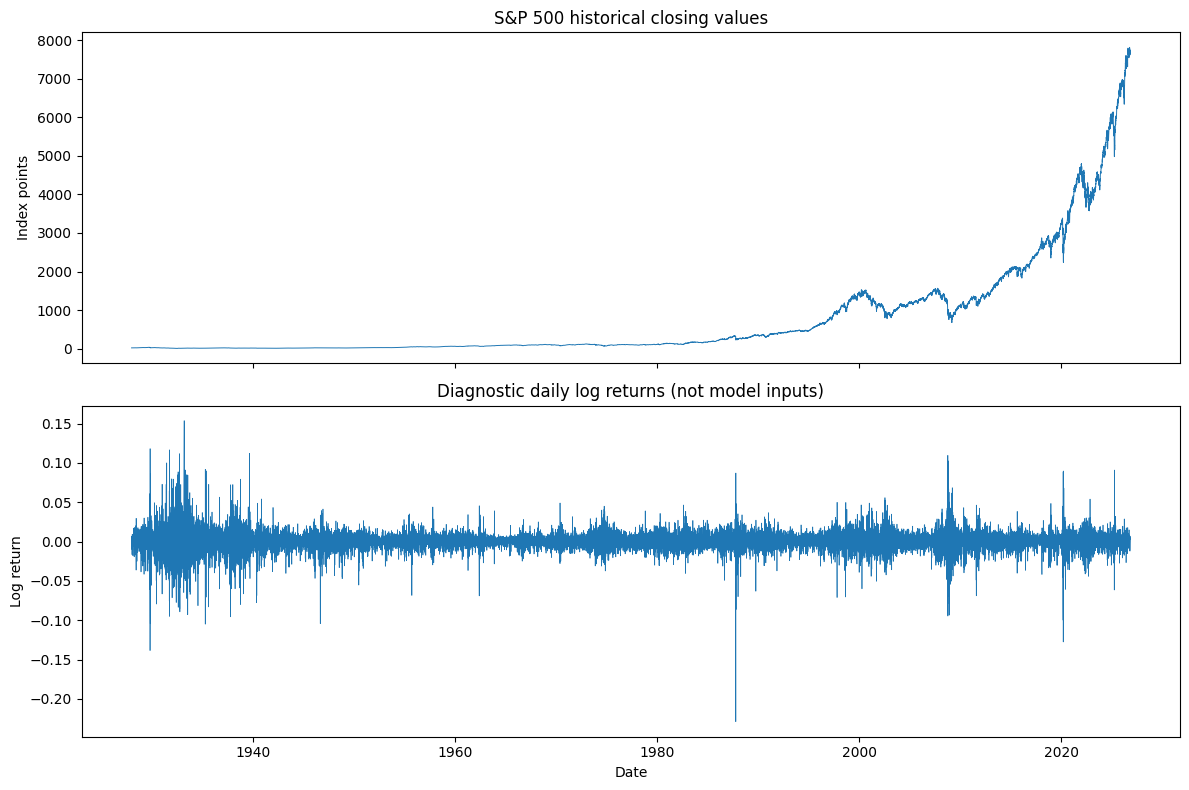

In [8]:
fig,ax=plt.subplots(2,1,figsize=(12,8),sharex=True)
ax[0].plot(df["Date"],df["Close"],lw=.7);ax[0].set(title="S&P 500 historical closing values",ylabel="Index points")
ax[1].plot(df["Date"],df["log_return_diagnostic"],lw=.5);ax[1].set(title="Diagnostic daily log returns (not model inputs)",ylabel="Log return",xlabel="Date")
plt.tight_layout();plt.savefig(OUT / "quality_overview.png",dpi=160);plt.show()

## 7. Export clean full-history series and metadata
The shared `sp500_clean_full_history.csv` contains **Date and Close only**, preserving every valid observed date. Additional diagnostics are separate files. The teammate responsible for time series analysis can use this file. No split or historical removal occurs here.

In [9]:
clean = df[["Date","Close"]].copy()
assert clean["Date"].is_monotonic_increasing and clean["Date"].is_unique
assert clean["Close"].notna().all() and (clean["Close"]>0).all()
clean.to_csv(OUT / "sp500_clean_full_history.csv",index=False,date_format="%Y-%m-%d")
metadata = {"source_url":"https://finance.yahoo.com/quote/%5EGSPC/history/","series_identifier":"^GSPC","access_date_utc":ACCESS_DATE,"requested_start":"1927-12-30","actual_start":str(clean["Date"].min().date()),"actual_end":str(clean["Date"].max().date()),"sample_size":len(clean),"exact_duplicate_rows_removed":len(exact_duplicates),"weekday_gaps_unverified":len(weekday_gaps),"outliers_flagged_not_removed":int(df["outlier_flag_review"].sum()),"history_cutoff_applied":False,"train_validation_test_split_applied":False,"package_versions":{p:im.version(p) for p in ["yfinance","pandas","numpy","matplotlib"]},"python":platform.python_version()}
(OUT / "metadata.json").write_text(json.dumps(metadata,indent=2))
print(json.dumps(metadata,indent=2))

{
  "source_url": "https://finance.yahoo.com/quote/%5EGSPC/history/",
  "series_identifier": "^GSPC",
  "access_date_utc": "2026-10-28",
  "requested_start": "1927-12-30",
  "actual_start": "1927-12-30",
  "actual_end": "2026-10-27",
  "sample_size": 24823,
  "exact_duplicate_rows_removed": 0,
  "weekday_gaps_unverified": 960,
  "outliers_flagged_not_removed": 110,
  "history_cutoff_applied": false,
  "train_validation_test_split_applied": false,
  "package_versions": {
    "yfinance": "0.2.66",
    "pandas": "2.2.3",
    "numpy": "2.1.3",
    "matplotlib": "3.10.0"
  },
  "python": "3.13.18"
}


## 8. Download all outputs as ZIP
In Colab this will download the prepared dataset, quality-review files, metadata, and plot.

In [10]:
import shutil
archive = shutil.make_archive("sp500_preparation_outputs","zip",OUT)
print("Created:",archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Not in Colab; ZIP is available locally.")

Created: /content/sp500_preparation_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
!pip -q install pandas_market_calendars

import pandas as pd
import pandas_market_calendars as mcal

# Load your gap review file
gaps = pd.read_csv("weekday_gaps_review.csv")
gaps["Date"] = pd.to_datetime(gaps["Date"])

# NYSE calendar
nyse = mcal.get_calendar("NYSE")

# Check whether each date was a scheduled trading day
schedule = nyse.schedule(
    start_date=gaps["Date"].min(),
    end_date=gaps["Date"].max()
)

trading_dates = pd.DatetimeIndex(schedule.index).normalize()

gaps["calendar_result"] = gaps["Date"].apply(
    lambda d: (
        "Expected trading day - investigate"
        if d.normalize() in trading_dates
        else "Calendar closure - verify historically"
    )
)

print(gaps["calendar_result"].value_counts())

gaps.to_csv("weekday_gaps_calendar_checked.csv", index=False)

calendar_result
Calendar closure - verify historically    960
Name: count, dtype: int64
